Why Sliding Windows Aren't Always Enough
While a sliding window is great for hard caps, it has a major flaw: it deletes old context completely. If a user mentioned their database password preference or a core architectural requirement 10 turns ago, a sliding window forgets it.

A Summarization Node solves this by having an LLM read the older messages, compress them into a running summary string, and prune the raw message array.

In [39]:
from langgraph.graph import END, StateGraph
from langgraph.graph.message import RemoveMessage
from typing_extensions import Annotated, TypedDict
import operator
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import AIMessage, HumanMessage


In [40]:
# 1. State holding both messages and the accumulated summary
class State(TypedDict):
  messages: Annotated[list, operator.add]
  summary: str

In [41]:
# 2. Summarization Node
def summarize_conversation(state: State):
  summary = state.get("summary", "")
  messages = state["messages"]

  # If message count exceeds threshold (e.g., 6 messages)
  if len(messages) > 6:
    print(
        "\n--- [Summarization Node Triggered] Compressing old history ---"
    )

    # In production, you would call an LLM here:
    # response = model.invoke(f"Summarize this conversation given existing summary: {summary}\nMessages: {messages[:-2]}")
    # new_summary = response.content

    # Simulating the generated summary update
    new_summary = (
        summary
        + " [Summary: User discussed FastAPI backend architecture and database"
        " models.]"
    )

    # Prune older messages, keeping only the last 2 for immediate context
    messages_to_remove = [RemoveMessage(id=m.id) for m in messages[:-2]]

    return {"summary": new_summary, "messages": messages_to_remove}

  return {}

In [42]:
# 3. Model Node
def model_node(state: State):
  print(
      f"\n--- [Model Node Running] Active Summary: {state.get('summary', 'None')} ---"
  )
  print(f"Active message count in state: {len(state['messages'])}")
  last_msg = state["messages"][-1]
  content = getattr(last_msg, "content", str(last_msg))

  return {"messages": [AIMessage(content=f"Acknowledged request: {content}")]}

In [43]:
# 3. Build Graph
workflow = StateGraph(State)

workflow.add_node("summarizer", summarize_conversation)
workflow.add_node("model", model_node)

workflow.set_entry_point("summarizer")
workflow.add_edge("summarizer", "model")
workflow.add_edge("model", END)

app = workflow.compile(checkpointer=InMemorySaver())

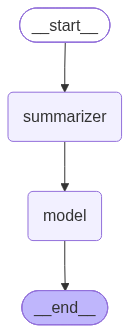

In [44]:
app

#### How Summarization Differs from Sliding Windows:
Preservation of Core Facts: Instead of losing early technical constraints, they are baked into the summary string stored in state.

Prompt Injection: When your model node runs, you inject both the summary and the remaining active messages into the system prompt, giving the agent full historical context without blowing token limits.

In [45]:
# 5. Run Test Session
if __name__ == "__main__":
  config = {"configurable": {"thread_id": "summary_test_1"}}

  # Initial prompt with 5 messages with explicit IDs (required for RemoveMessage)
  initial_messages = [
      HumanMessage(content="Hello", id="msg_1"),
      AIMessage(content="Hi there!", id="msg_2"),
      HumanMessage(content="What is FastAPI?", id="msg_3"),
      AIMessage(content="It is a high-performance Python framework.", id="msg_4"),
      HumanMessage(
          content="Can you write a database model for it?", id="msg_5"
      ),
  ]

  print("Invoking graph with 5 initial messages...")
  result = app.invoke(
      {"messages": initial_messages, "summary": ""}, config=config
  )

  print("\n================ FINAL STATE RESULT ================")
  print(f"Stored Summary: {result.get('summary')}\n")
  print("Remaining Active Messages in Memory:")
  for msg in result["messages"]:
    msg_id = getattr(msg, "id", "N/A")
    print(f" - [ID: {msg_id}] {msg.__class__.__name__}: {msg.content}")

Invoking graph with 5 initial messages...

--- [Model Node Running] Active Summary:  ---
Active message count in state: 5

================ FINAL STATE RESULT ================
Stored Summary: 

Remaining Active Messages in Memory:
 - [ID: msg_1] HumanMessage: Hello
 - [ID: msg_2] AIMessage: Hi there!
 - [ID: msg_3] HumanMessage: What is FastAPI?
 - [ID: msg_4] AIMessage: It is a high-performance Python framework.
 - [ID: msg_5] HumanMessage: Can you write a database model for it?
 - [ID: None] AIMessage: Acknowledged request: Can you write a database model for it?


The Model Node can use the saved summary by including it in the prompt sent to the LLM, along with the recent messages.
For example:
from langchain_core.messages import SystemMessage

def model_node(state: State):
##### Inject previous conversation summary
    prompt = [
        SystemMessage(
            content=f"Previous conversation summary: {summary}"
        )
    ] + messages

    response = llm.invoke(prompt)

    return {"messages": [response]}


Here, the LLM receives two kinds of context:
- Summary: Important information from older conversations.
- Messages: The most recent conversation turns.
For example, even if the original messages about PostgreSQL were removed, the LLM could still know the user is building a FastAPI application with PostgreSQL, provided that information was preserved in the summary.
Important: Saving summary in the state alone isn't enough. We must explicitly pass it to the LLM.